# Parametrization of eccNet
The original version of the eccNet uses fixed values for its parameters deg2px and ecc_slope. That approach does not regard display size, resolution and distance to the viewer. In this work we therefore aim to extend the current eccNet parametrization in order to model the receptive field sizes of marcaque monkeys at different stages of visual cortex more accurately. This enhances the comparability between eccNet and human experiments.  

## 1. Finding Values

### New Parameters

In [64]:
import numpy as np
import matplotlib.pyplot as plt
import math

In [65]:
# Shared layer metadata: V1/V2/V4 correspond to index 2/3/4 of the 5-element eccNet
# parameter lists (index 0/1 unused, kept for compatibility with ecc_net.py's format)
LAYERS = (2, 3, 4)
LAYER_NAMES = {2: "V1", 3: "V2", 4: "V4"}
LAYER_COLORS = {2: "tab:green", 3: "tab:orange", 4: "tab:red"}

# deg2px halves with each successive layer (see deg2px computation below, and
# eccParamDefault in ecc_net.py)
DEG2PX_LAYER_DIVISORS = [1, 2, 4, 8, 16]

# Our parametrization
FOVEA_SIZE = 4   # deg
RF_MIN = 2       # px
RF_QUANT = 1     # deg

# eccParamDefault from vs_model/ecc_net.py (lines 241-248) - fixed reference values,
# independent of display geometry
ECCNET_DEG2PX = [round(30.0 / d) for d in DEG2PX_LAYER_DIVISORS]
ECCNET_ECC_SLOPE = [0, 0, 3.5 * 0.02, 8 * 0.02, 16 * 0.02]
ECCNET_RF_MIN = 2
ECCNET_FOVEA_SIZE = 4
ECCNET_RF_QUANT = 1

# Every pooling layer in ecc_net.py (pool_layer / CentreDependentPooling2D) uses this
# stride (eccParamDefault['stride'] = [2]*5), regardless of parametrization
POOL_STRIDE = 2

# block1_conv..block5_conv (vs_model/ecc_net.py) each run before the pooling layer of the
# same depth: 2, 2, 3, 3, 3 Conv2D layers, all 3x3 with stride 1 and padding='same'
CONV_LAYERS_PER_DEPTH = [2, 2, 3, 3, 3]
CONV_KERNEL_SIZE = 3

# Per-layer fovea_size matching the physiological breakpoints (see PHYSIO_RF_PARAMS,
# section 2.3) instead of the single global fovea_size ecc_net.py currently supports.
# Index 0/1 unused (ecc_slope=0 there, so their value doesn't affect anything).
FOVEA_SIZE_PER_LAYER = [FOVEA_SIZE, FOVEA_SIZE, 7, 4, 3]  # V1, V2, V4 thresholds

In [66]:
# Set by the user 
display_dist = 470   # mm
resolution = (1920, 1080) # Full HD 
display_size = (332, 187) # mm


print(f"Display Distance:   {display_dist} mm")
print(f"Display Resolution: {resolution[0]}x{resolution[1]} px")
print(f"Display Size:       {display_size[0]}x{display_size[1]} mm")

Display Distance:   470 mm
Display Resolution: 1920x1080 px
Display Size:       332x187 mm


### ECC_SLOPE
The slope values are sourced directly from the marcaque paper (s. diagram)

In [67]:
ecc_slope_RF = [0, 0, 1/6, 3/6, 5/6]  # physiological RF-size(dva) slopes for V1, V2, V4
ecc_slope = [
    ecc_slope_RF[i] - ecc_slope_RF[i-1] if i > 0 else ecc_slope_RF[i]
    for i in range(len(ecc_slope_RF))
]
print(f'ecc slopes: {ecc_slope}')

ecc slopes: [0, 0, 0.16666666666666666, 0.33333333333333337, 0.33333333333333337]


In [68]:
# Sanity check: undoing the differencing (cumulative sum) must reproduce the
# original physiological slopes.
reconstructed = np.cumsum(ecc_slope)
assert np.allclose(reconstructed, ecc_slope_RF), f"{reconstructed} != {ecc_slope_RF}"
print(f"reconstructed ecc_slope_RF: {reconstructed}")

reconstructed ecc_slope_RF: [0.         0.         0.16666667 0.5        0.83333333]


### DEG2PX
Instead of using the tan(x) function, we use a linear approximation of tan(x) within the relevant value range 0°... 33°.

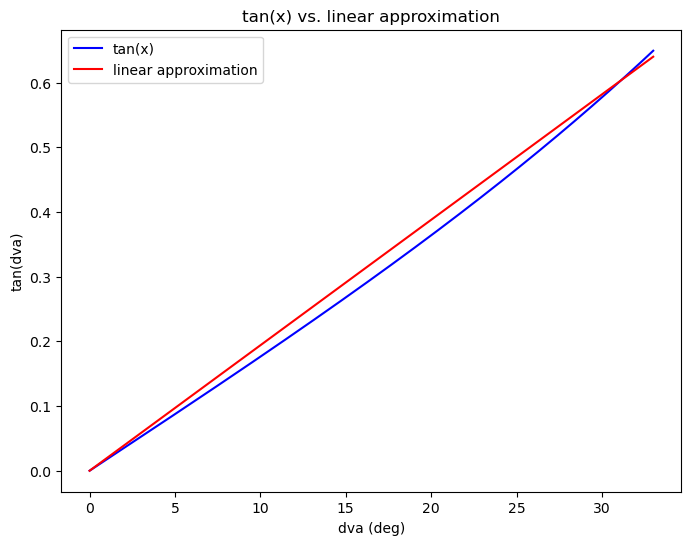

linear approximation of tan:
y = 0.01940 * x


In [69]:
dva = np.linspace(0, 33, 330)
tan_dva = np.tan(np.radians(dva))

tan_c, _ = np.polyfit(dva, tan_dva, 1)
linear_approx = tan_c * dva 

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(dva, tan_dva, color='blue', label="tan(x)")
ax.plot(dva, linear_approx, color='red', label="linear approximation")

ax.set_xlabel("dva (deg)")
ax.set_ylabel("tan(dva)")
ax.set_title("tan(x) vs. linear approximation")
ax.legend()

plt.show()

print(f"linear approximation of tan:")
print(f'y = {tan_c:.5f} * x')

In [70]:
mm2px = resolution[0] / display_size[0]

deg2px_0 = display_dist * tan_c * mm2px
deg2px = [deg2px_0 / d for d in DEG2PX_LAYER_DIVISORS]

print(f"mm2px:   {mm2px} px/mm")
print(f"deg2px:  {deg2px_0:.2f} px/deg")

mm2px:   5.783132530120482 px/mm
deg2px:  52.73 px/deg


In the original parametrization deg2px is set to 30 px/dva. In the following it is visualized what display distances (mm) and resolutions (px/mm) that deg2px value corresponds to. So, these are the values that the researchers purposely or unpurposely modeled. 

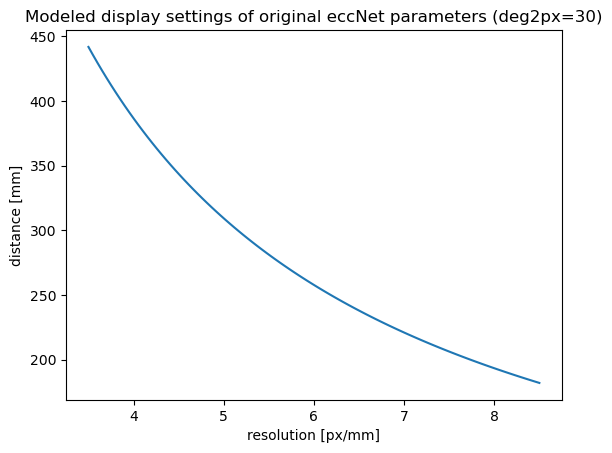

In [71]:
px_per_mm_range = np.linspace(3.5, 8.5, 100)
distance = ECCNET_DEG2PX[0] / (tan_c * px_per_mm_range)

plt.xlabel('resolution [px/mm]')
plt.ylabel('distance [mm]')
plt.title("Modeled display settings of original eccNet parameters (deg2px=30)")

plt.plot(px_per_mm_range, distance)
plt.show()  

## 2. Visualizing Effects

### 2.1 Kernel Sizes
Within the fovea, the receptive field size is constant rf_min. However, the width of the fovea is given in degrees and therefore varies throughout the layers as deg2px is layer-dependant. Further, the receptive field size *radius* increases by ecc_slope, whereas the resulting kernel sizes (2 * RF_radius) therefore increaes by 2 * ecc_slope. 

In [72]:
def dva_to_px(dva, deg2px):
    """ecc_net.py line 66: dva -> px conversion (radius/position)."""
    return dva * deg2px / 2

def dva_size_to_px(dva_size, deg2px):
    return dva_size * deg2px

def rf_diameter_px(ecc_px, slope, fovea_radius_px, rf_min):
    """ecc_net.py line 92: kernel diameter in px beyond the fovea edge."""
    return rf_min + np.maximum(0, 2 * slope * (ecc_px - fovea_radius_px))

def effective_rf_diameter_px(ecc_px_base, ecc_slope, deg2px, fovea_size, rf_min, stride,
                              conv_layers_per_depth, conv_kernel_size, up_to_layer):
    rf = 1
    jump = 1
    for layer in range(up_to_layer + 1):
        for _ in range(conv_layers_per_depth[layer]):
            rf = rf + (conv_kernel_size - 1) * jump

        d2p = deg2px[layer]
        fovea_size_l = fovea_size[layer] if isinstance(fovea_size, (list, tuple)) else fovea_size
        fovea_radius_px = dva_to_px(fovea_size_l, d2p)
        ecc_px_layer = ecc_px_base * d2p / deg2px[0]
        kernel = rf_diameter_px(ecc_px_layer, ecc_slope[layer], fovea_radius_px, rf_min)
        rf = rf + (kernel - 1) * jump
        jump = jump * stride
    return rf

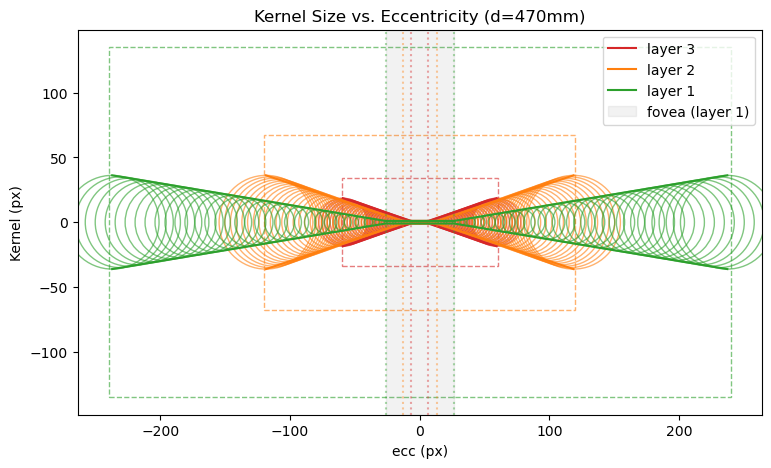

In [73]:
from matplotlib.patches import Circle, Rectangle

def plot_kernel_sizes(deg2px, ecc_slope, rf_min, resolution, fovea_size=FOVEA_SIZE, rf_quant=RF_QUANT,
                       layers=LAYERS, title="Kernel Size vs. Eccentricity", show_pre_pool_stages=False):
    fig, ax = plt.subplots(figsize=(10, 5))

    layer_borders = {}
    layer_y_borders = {}
    for layer in sorted(layers, reverse=True):  # largest RF (red) first, drawn behind smaller ones
        color = LAYER_COLORS[layer]
        slope = ecc_slope[layer]
        d2p = deg2px[layer]
        fovea_radius_px = dva_to_px(fovea_size, d2p)
        step = dva_to_px(rf_quant, d2p)

        border_px = (resolution[0] / 2) / DEG2PX_LAYER_DIVISORS[layer]
        y_border_px = (resolution[1] / 2) / DEG2PX_LAYER_DIVISORS[layer]
        layer_borders[layer] = border_px
        layer_y_borders[layer] = y_border_px

        fovea_pts = np.arange(-fovea_radius_px, fovea_radius_px + step, step)  # flat rf_min region
        fovea_pts = fovea_pts[np.abs(fovea_pts) <= fovea_radius_px]

        n_steps_layer = int(np.floor((border_px - fovea_radius_px) / step))
        growth_steps = np.arange(1, n_steps_layer + 1) * step
        growth_pts = np.concatenate([fovea_radius_px + growth_steps, -(fovea_radius_px + growth_steps)])

        ecc_vals = np.concatenate([fovea_pts, growth_pts])
        ecc_vals = ecc_vals[np.abs(ecc_vals) <= border_px]

        rf_vals = rf_diameter_px(np.abs(ecc_vals), slope, fovea_radius_px, rf_min)

        for e, rf in zip(ecc_vals, rf_vals):
            ax.add_patch(Circle((e, 0), rf / 2, fill=False, color=color, alpha=0.6))

        order = np.argsort(ecc_vals)
        ax.plot(ecc_vals[order], rf_vals[order] / 2, color=color, label=f"layer {layer-1}")
        ax.plot(ecc_vals[order], -rf_vals[order] / 2, color=color)

        ax.axvline(fovea_radius_px, color=color, linestyle=':', alpha=0.4)
        ax.axvline(-fovea_radius_px, color=color, linestyle=':', alpha=0.4)
        ax.add_patch(Rectangle((-border_px, -y_border_px), 2 * border_px, 2 * y_border_px,
                               fill=False, edgecolor=color, linestyle='--', alpha=0.6))

    common_fovea_radius_px = dva_to_px(fovea_size, deg2px[layers[0]])
    ax.axvspan(-common_fovea_radius_px, common_fovea_radius_px, color='gray', alpha=0.1, label='fovea (layer 1)')

    pre_stage_borders = []
    if show_pre_pool_stages:
        pre_stage_labels = {0: 'original image', 1: 'after 1st max pool'}
        for pre_layer, label in pre_stage_labels.items():
            pre_border_px = (resolution[0] / 2) / DEG2PX_LAYER_DIVISORS[pre_layer]
            pre_y_border_px = (resolution[1] / 2) / DEG2PX_LAYER_DIVISORS[pre_layer]
            pre_stage_borders.append((pre_border_px, pre_y_border_px))
            ax.add_patch(Rectangle((-pre_border_px, -pre_y_border_px), 2 * pre_border_px, 2 * pre_y_border_px,
                                   fill=False, edgecolor='gray', linestyle='--', alpha=0.6, label=label))

    max_ecc_all = max(list(layer_borders.values()) + [b[0] for b in pre_stage_borders])
    max_y_all = max(list(layer_y_borders.values()) + [b[1] for b in pre_stage_borders])

    ax.set_xlabel("ecc (px)")
    ax.set_ylabel("Kernel (px)")
    ax.set_title(title)
    margin = 1.1
    ax.set_xlim(-max_ecc_all * margin, max_ecc_all * margin)
    ax.set_ylim(-max_y_all * margin, max_y_all * margin)
    ax.set_aspect('equal', adjustable='box')
    ax.legend()

    plt.show()

plot_kernel_sizes(deg2px, ecc_slope, RF_MIN, resolution, title=f"Kernel Size vs. Eccentricity (d={display_dist}mm)", show_pre_pool_stages=False)

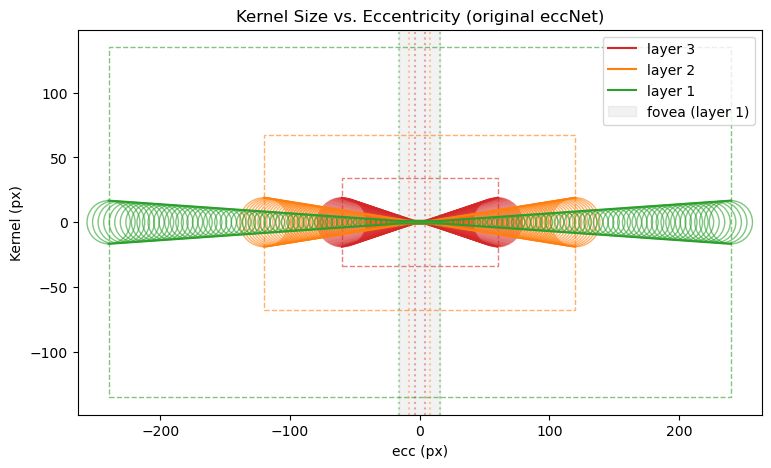

In [74]:
plot_kernel_sizes(ECCNET_DEG2PX, ECCNET_ECC_SLOPE, ECCNET_RF_MIN, resolution,
                   fovea_size=ECCNET_FOVEA_SIZE, rf_quant=ECCNET_RF_QUANT,
                   title="Kernel Size vs. Eccentricity (original eccNet)", show_pre_pool_stages=False)

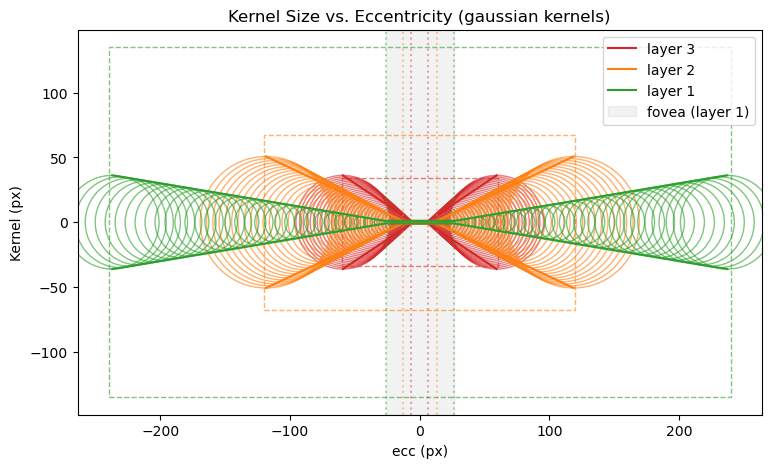

In [75]:
ecc_slope_gaussian = [0, 0, 1/6, math.sqrt(8)/6, 4/6]

plot_kernel_sizes(deg2px, ecc_slope_gaussian, ECCNET_RF_MIN, resolution,
                   fovea_size=ECCNET_FOVEA_SIZE, rf_quant=ECCNET_RF_QUANT,
                   title="Kernel Size vs. Eccentricity (gaussian kernels)", show_pre_pool_stages=False)

### 2.2 Cumulative RF Size
`eccnet_ecc_slope` above uses the raw (non-differenced) physiological values directly
as `ecc_slope` per layer, so it does not compensate the kernel cascade. The corrected
`ecc_slope` computed above is differenced instead, so that the *sum* of each layer's
marginal kernel contribution (in degrees) reconstructs the target cumulative RF(ecc).
This checks that empirically.

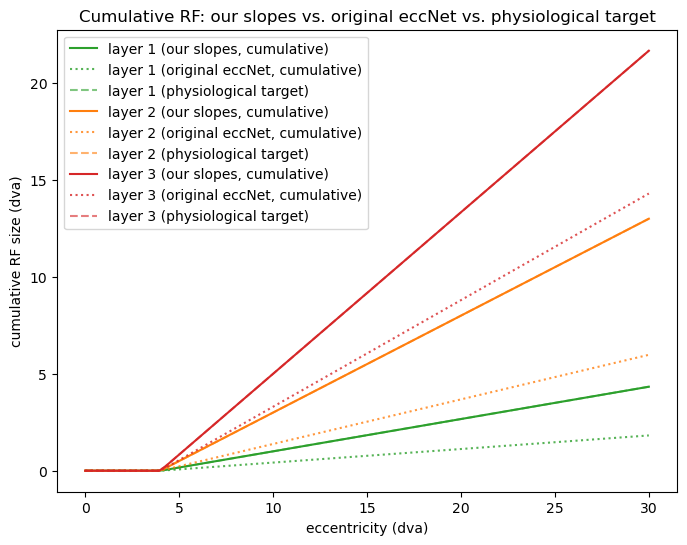

In [76]:
def cumulative_rf_deg(ecc_deg, ecc_slope, fovea_size, layers=LAYERS):
    """Cumulative RF size (dva) at each layer, summing marginal per-layer kernel
    contributions. Mirrors ecc_net.py line 92 exactly: rf_sizes = rf_min +
    ecc_slope*(ecc*2 - fovea_size*deg2px). Converting that to dva via
    ecc_px = ecc_dva*deg2px/2 (line 66) makes the *2 and the /deg2px cancel,
    leaving ecc_slope * (ecc_dva - fovea_size) (rf_min omitted, negligible here)."""
    cum = np.zeros_like(ecc_deg)
    curves = {}
    for layer in range(max(layers) + 1):
        k_deg = ecc_slope[layer] * np.maximum(0, ecc_deg - fovea_size)
        cum = cum + k_deg
        if layer in layers:
            curves[layer] = cum.copy()
    return curves

ecc_deg = np.linspace(0, 30, 100)
cum_curves = cumulative_rf_deg(ecc_deg, ecc_slope, fovea_size=FOVEA_SIZE)
cum_curves_eccnet = cumulative_rf_deg(ecc_deg, ECCNET_ECC_SLOPE, fovea_size=ECCNET_FOVEA_SIZE)

fig, ax = plt.subplots(figsize=(8, 6))
for layer in cum_curves:
    color = LAYER_COLORS[layer]
    ax.plot(ecc_deg, cum_curves[layer], color=color, label=f"layer {layer-1} (our slopes, cumulative)")
    ax.plot(ecc_deg, cum_curves_eccnet[layer], ':', color=color, alpha=0.8,
             label=f"layer {layer-1} (original eccNet, cumulative)")
    target_slope = ecc_slope_RF[layer]
    ax.plot(ecc_deg, target_slope * np.maximum(0, ecc_deg - FOVEA_SIZE), '--',
             color=color, alpha=0.6, label=f"layer {layer-1} (physiological target)")

ax.set_xlabel("eccentricity (dva)")
ax.set_ylabel("cumulative RF size (dva)")
ax.set_title("Cumulative RF: our slopes vs. original eccNet vs. physiological target")
ax.legend()
plt.show()

### 2.3 Display Simulation: RF Circles at V1/V2/V3
Simulates the display (rectangle, size = `resolution`) with fixation at the center.
For a set of eccentricities, draws the *effective* (true cumulative) RF size (diameter)
as a circle — once using the original eccNet `ecc_slope`, once using our compensated
`ecc_slope`, plus the physiological target RF size (macaque data) for reference. Unlike
2.1 (which shows each layer's own kernel size in isolation) and 2.2 (which only checks
that `ecc_slope`'s differencing reconstructs the physiological target slopes in
degree-space, by construction), this composes the actual receptive field across
`ecc_net.py`'s full layer sequence — `block{N}_conv`'s 3x3 conv layers *and* the pooling
layer at each depth (`RF_l = RF_{l-1} + (kernel_l - 1) * jump_{l-1}`) — so conv layers,
per-layer `rf_min` and `stride` are all accounted for instead of assumed negligible. The
eccNet and our curves use their respective display-geometry-derived `deg2px` (from
above); the physiological target is computed once using our real display's `deg2px`,
since it represents the ground truth independent of parametrization.

In [77]:
# Physiological RF-size(eccentricity) targets per area (macaque data), in degrees.
# (threshold_deg, floor_deg, slope): RF = floor for ecc <= threshold, else slope * ecc
# Slopes match ecc_slope_RF (Sec. 1) so "ours" and the physiological target are
# calibrated to the same macaque data.
PHYSIO_RF_PARAMS = {
    2: (7, 1.0, ecc_slope_RF[2]),   # V1
    3: (4, 2.0, ecc_slope_RF[3]),   # V2
    4: (3, 2.5, ecc_slope_RF[4]),   # V4
}

def physiological_rf_deg(ecc_deg, layer):
    threshold, floor, slope = PHYSIO_RF_PARAMS[layer]
    return np.where(ecc_deg <= threshold, floor, slope * ecc_deg)

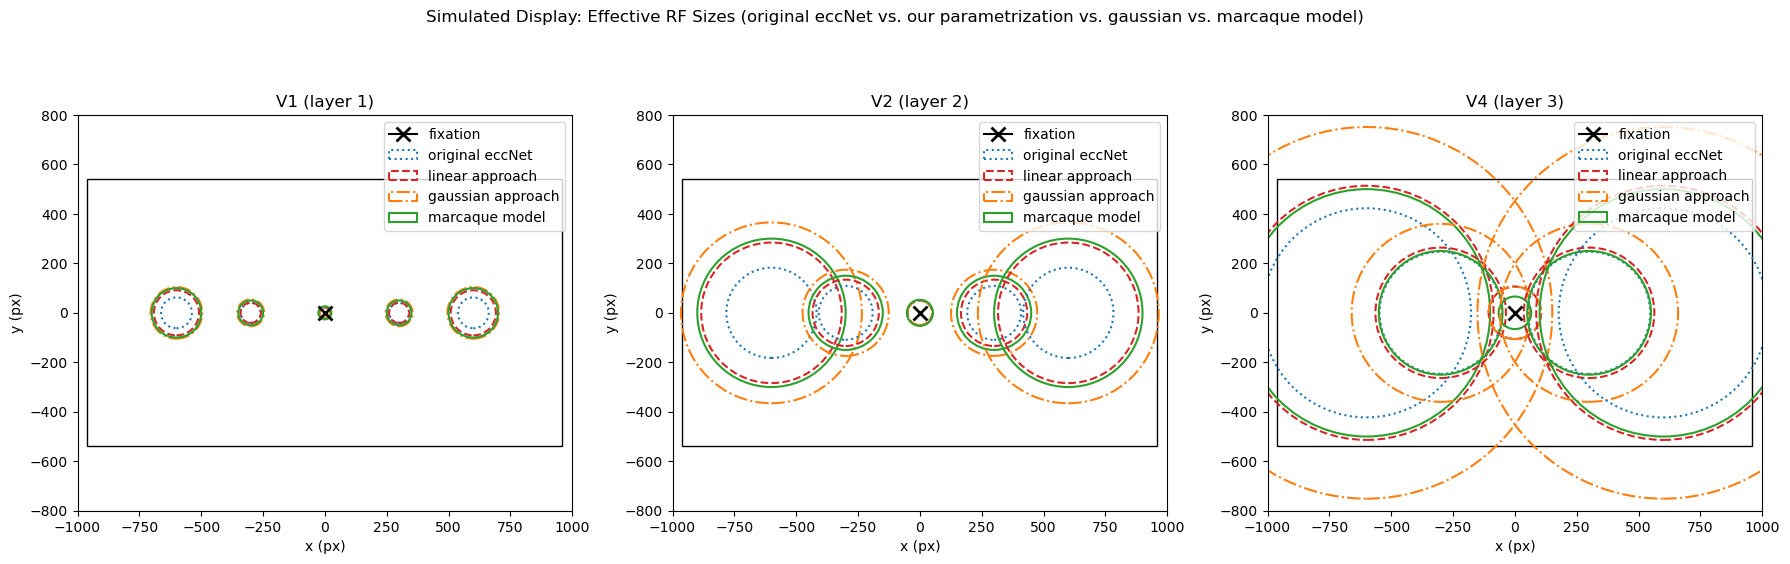

In [78]:
from matplotlib.patches import Rectangle

ecc_px_steps = np.arange(0, 900, 300)
ecc_px_vals = np.concatenate([-ecc_px_steps[::-1], ecc_px_steps[1:]])

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, layer in zip(axes, LAYERS):
    half_w, half_h = resolution[0] / 2, resolution[1] / 2
    ax.add_patch(Rectangle((-half_w, -half_h), resolution[0], resolution[1],
                            fill=False, color='black', linewidth=1))
    ax.plot(0, 0, marker='x', color='black', markersize=10, markeredgewidth=2, label='fixation')

    for i, x_px in enumerate(ecc_px_vals):
        rf_eccnet = effective_rf_diameter_px(abs(x_px), ECCNET_ECC_SLOPE, ECCNET_DEG2PX,
                                              ECCNET_FOVEA_SIZE, ECCNET_RF_MIN, POOL_STRIDE,
                                              CONV_LAYERS_PER_DEPTH, CONV_KERNEL_SIZE, layer)
        rf_ours = effective_rf_diameter_px(abs(x_px), ecc_slope, deg2px,
                                            FOVEA_SIZE_PER_LAYER, RF_MIN, POOL_STRIDE,
                                            CONV_LAYERS_PER_DEPTH, CONV_KERNEL_SIZE, layer)
        rf_gaussian = effective_rf_diameter_px(abs(x_px), ecc_slope_gaussian, deg2px,
                                                FOVEA_SIZE, RF_MIN, POOL_STRIDE,
                                                CONV_LAYERS_PER_DEPTH, CONV_KERNEL_SIZE, layer)
        ecc_deg = abs(x_px) * 2 / deg2px[0]
        rf_physio = dva_size_to_px(physiological_rf_deg(ecc_deg, layer), deg2px[0])

        ax.add_patch(Circle((x_px, 0), rf_eccnet / 2, fill=False, color='tab:blue',
                             linestyle=':', linewidth=1.5,
                             label='original eccNet' if i == 0 else None))
        ax.add_patch(Circle((x_px, 0), rf_ours / 2, fill=False, color='tab:red',
                             linestyle='--', linewidth=1.5,
                             label='linear approach' if i == 0 else None))
        ax.add_patch(Circle((x_px, 0), rf_gaussian / 2, fill=False, color='tab:orange',
                             linestyle='-.', linewidth=1.5,
                             label='gaussian approach' if i == 0 else None))
        ax.add_patch(Circle((x_px, 0), rf_physio / 2, fill=False, color='tab:green',
                             linewidth=1.5,
                             label='marcaque model' if i == 0 else None))

    ax.set_xlim(-1000, 1000)
    ax.set_ylim(-800, 800)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel("x (px)")
    ax.set_ylabel("y (px)")
    ax.set_title(f"{LAYER_NAMES[layer]} (layer {layer-1})")
    ax.legend(loc='upper right')

fig.suptitle("Simulated Display: Effective RF Sizes (original eccNet vs. our parametrization vs. gaussian vs. marcaque model)")
plt.tight_layout()
plt.show()

### 2.4 ecc_slope estimation w.r.t. gaussian receptive fields 

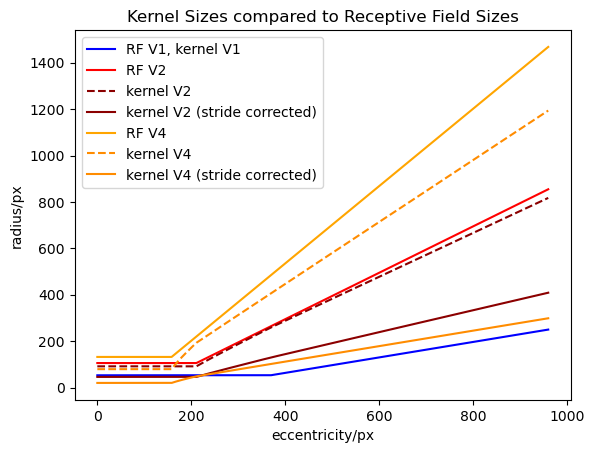

In [79]:
# Physiological Marcaque Model
fovea_size_deg = np.array([7, 4, 3])
rf_min_deg = np.array([1, 2, 2.5])
layer_slopes = np.array([ecc_slope_RF[layer] for layer in LAYERS])[:, None]

fovea_size_px = fovea_size_deg[:, None] * deg2px_0
rf_min_px = rf_min_deg[:, None] * deg2px_0

ecc = np.linspace(0, resolution[0]//2, 1000)
r = rf_min_px + np.maximum(0, layer_slopes * (2 * ecc - 2 * fovea_size_px))

# kernel sizes w.r.t. gaussian receptive fiel sizes of humans 
k_V1 = r[0]
k_V2 = np.sqrt(r[1]**2 - k_V1**2)
k_V4 = np.sqrt(r[2]**2 - k_V1**2 - k_V2**2)

plt.plot(ecc, r[0], label='RF V1, kernel V1', color='blue')
plt.plot(ecc, r[1], label='RF V2', color='red')
plt.plot(ecc, k_V2, label='kernel V2', color='darkred', linestyle='--')
plt.plot(ecc, k_V2 / 2, label='kernel V2 (stride corrected)', color='darkred')
plt.plot(ecc, r[2], label='RF V4', color='orange')
plt.plot(ecc, k_V4, label='kernel V4', color='darkorange', linestyle='--')
plt.plot(ecc, k_V4 / 4, label='kernel V4 (stride corrected)', color='darkorange')
plt.xlabel('eccentricity/px')
plt.ylabel('radius/px')
plt.title('Kernel Sizes compared to Receptive Field Sizes')
plt.legend()
plt.show()

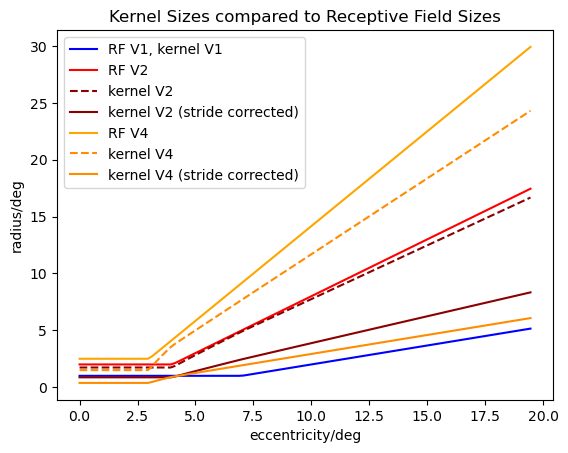

In [80]:
ecc_deg_max = math.degrees(math.atan((display_size[0]/2) / display_dist))
ecc = np.linspace(0, ecc_deg_max, 100)
rf_deg = rf_min_deg[:, None] + np.maximum(0, layer_slopes * (2 * ecc - 2 * fovea_size_deg[:, None]))

# kernel sizes w.r.t. gaussian receptive fiel sizes of humans 
k_V1 = rf_deg[0]
k_V2 = np.sqrt(rf_deg[1]**2 - k_V1**2)
k_V4 = np.sqrt(rf_deg[2]**2 - k_V1**2 - k_V2**2)

plt.plot(ecc, rf_deg[0], label='RF V1, kernel V1', color='blue')
plt.plot(ecc, rf_deg[1], label='RF V2', color='red')
plt.plot(ecc, k_V2, label='kernel V2', color='darkred', linestyle='--')
plt.plot(ecc, k_V2 / 2, label='kernel V2 (stride corrected)', color='darkred')
plt.plot(ecc, rf_deg[2], label='RF V4', color='orange')
plt.plot(ecc, k_V4, label='kernel V4', color='darkorange', linestyle='--')
plt.plot(ecc, k_V4 / 4, label='kernel V4 (stride corrected)', color='darkorange')
plt.xlabel('eccentricity/deg')
plt.ylabel('radius/deg')
plt.title('Kernel Sizes compared to Receptive Field Sizes')
plt.legend()
plt.show()

### 2.5 Effective RF Sizes on a Stimulus
Draws the stimulus `stimuli/lung.png` in its original size (image px) with fixation at the image centre. The fovea is drawn as a yellow circle, the *effective* RF size (see 2.3) as blue circles along the horizontal and vertical line through the image centre. Starting at the centre, each next circle is placed at the first eccentricity where it does not touch the previous one, so the circles never overlap along a line. Once for the original eccNet parametrization, once for ours.

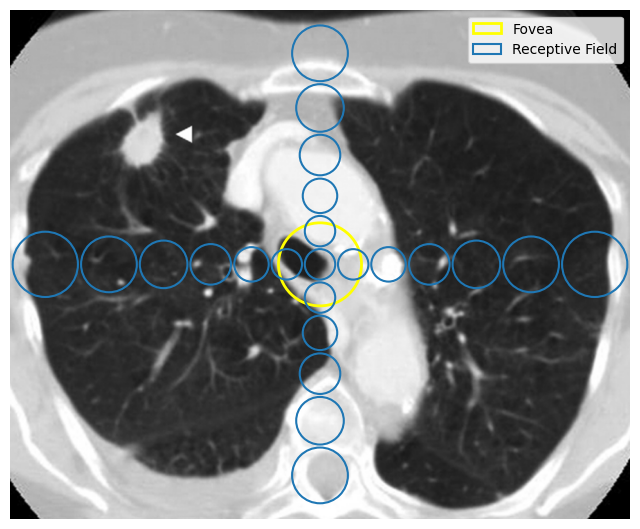

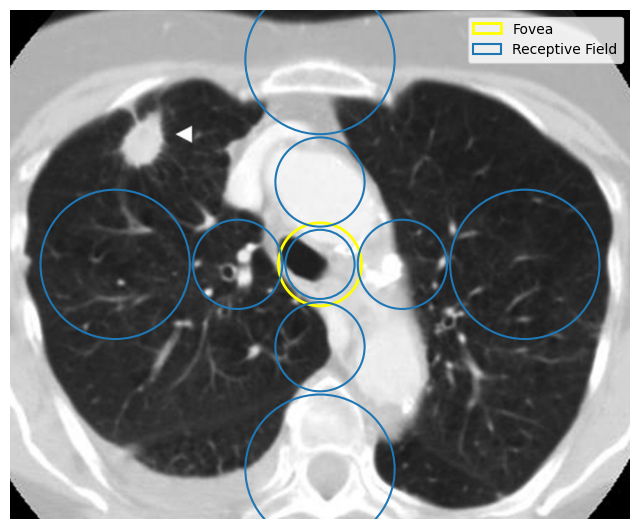

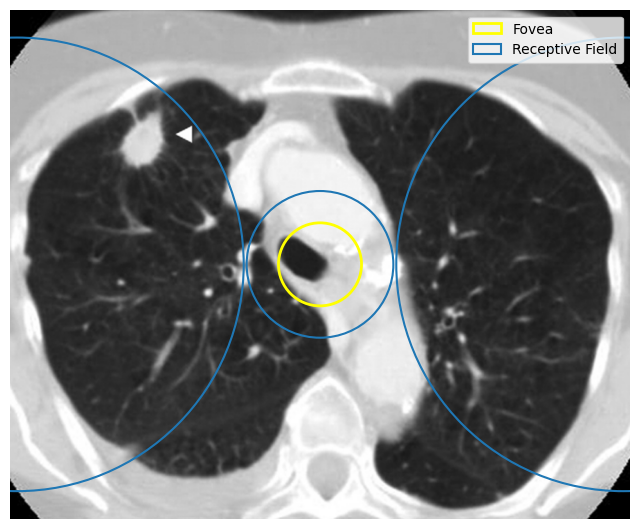

In [81]:
img = plt.imread('stimuli/lung.png')
img_h, img_w = img.shape[:2]

def rf_positions(rf_fn, max_ecc, gap=4):
    """Places RF circles from the centre outwards: each next circle is set at the first
    eccentricity (1 px steps) where it doesn't touch the previous one (+ gap)."""
    positions = [(0, rf_fn(0))]
    x = 0
    while True:
        prev_x, prev_d = positions[-1]
        x += 1
        while x <= max_ecc and x - rf_fn(x) / 2 < prev_x + prev_d / 2 + gap:
            x += 1
        if x > max_ecc:
            return positions
        positions.append((x, rf_fn(x)))
        assert x - prev_x >= (positions[-1][1] + prev_d) / 2

def plot_rf_on_image(title, ecc_slope, deg2px, fovea_size, rf_min):
    extent = (-img_w / 2, img_w / 2, img_h / 2, -img_h / 2)
    for layer in LAYERS:
        fig, ax = plt.subplots(figsize=(8, 7))
        ax.imshow(img, extent=extent)

        fovea_l = fovea_size[layer] if isinstance(fovea_size, (list, tuple)) else fovea_size
        ax.add_patch(Circle((0, 0), dva_to_px(fovea_l, deg2px[0]), fill=False, color='yellow',
                            linewidth=2, label='Fovea'))

        rf_fn = lambda e: effective_rf_diameter_px(e, ecc_slope, deg2px, fovea_size, rf_min, POOL_STRIDE,
                                                   CONV_LAYERS_PER_DEPTH, CONV_KERNEL_SIZE, layer)
        circles = [(0, 0, rf_fn(0))]
        for e, d in rf_positions(rf_fn, img_w / 2)[1:]:
            circles += [(e, 0, d), (-e, 0, d)]
        for e, d in rf_positions(rf_fn, img_h / 2)[1:]:
            circles += [(0, e, d), (0, -e, d)]
        for i, (x, y, d) in enumerate(circles):
            ax.add_patch(Circle((x, y), d / 2, fill=False, color='tab:blue', linewidth=1.5,
                                label='Receptive Field' if i == 0 else None))

        ax.set_xlim(extent[0], extent[1])
        ax.set_ylim(extent[2], extent[3])
        ax.set_aspect('equal')
        ax.axis('off')
        #ax.set_title(f"{title}: {LAYER_NAMES[layer]} (layer {layer-1})")
        ax.legend(loc='upper right')
        plt.show()

plot_rf_on_image("Effective RF sizes on stimulus (original eccNet)",
                 ECCNET_ECC_SLOPE, ECCNET_DEG2PX, ECCNET_FOVEA_SIZE, ECCNET_RF_MIN)


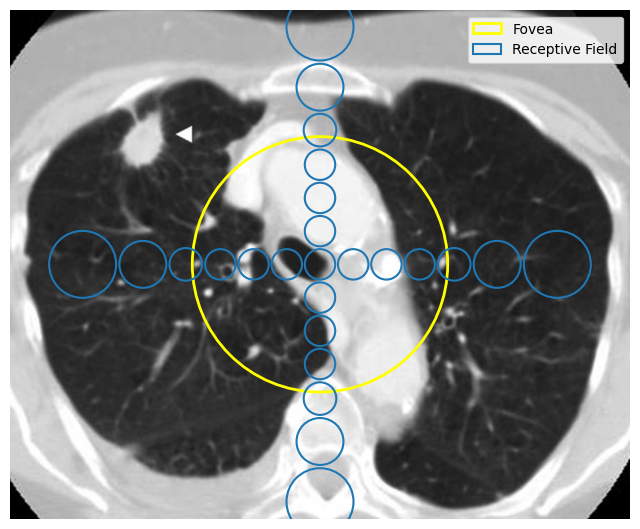

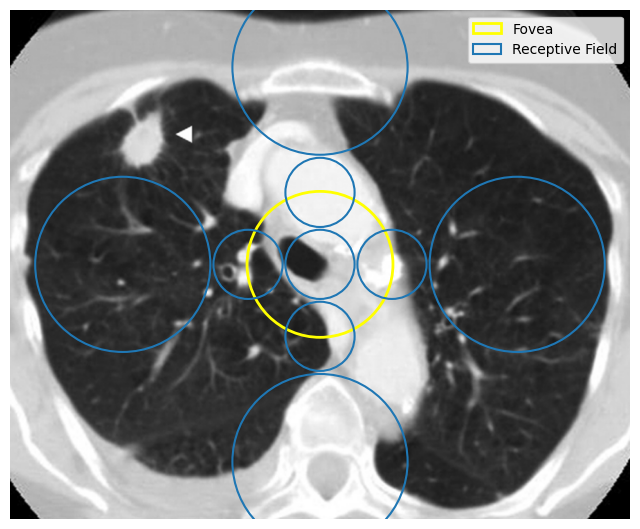

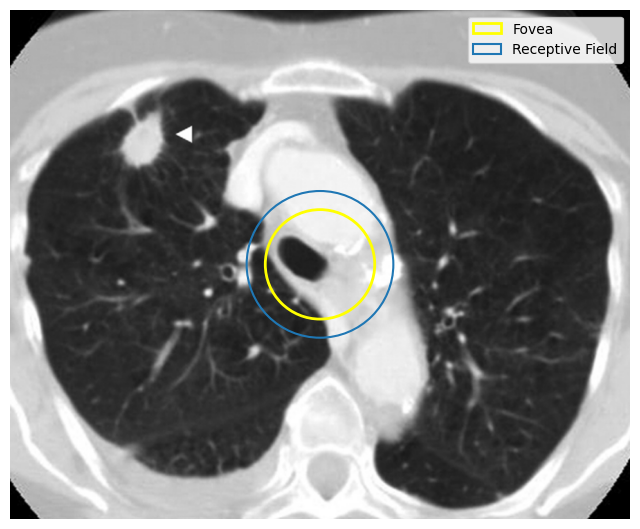

In [82]:
plot_rf_on_image(f"Effective RF sizes on stimulus (our parametrization, d={display_dist}mm)",
                 ecc_slope, deg2px, FOVEA_SIZE_PER_LAYER, RF_MIN)

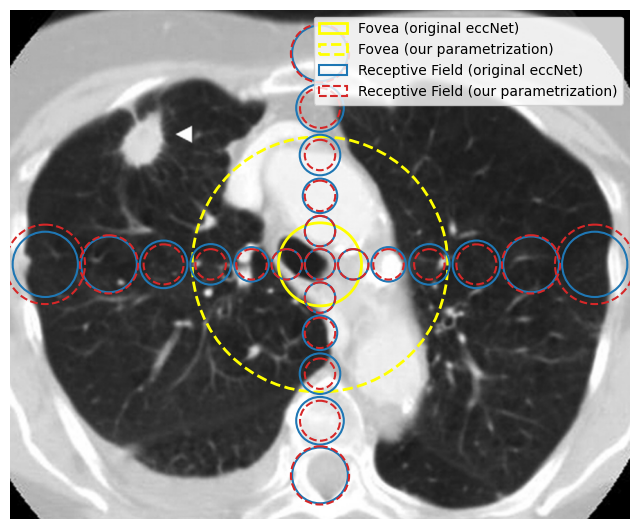

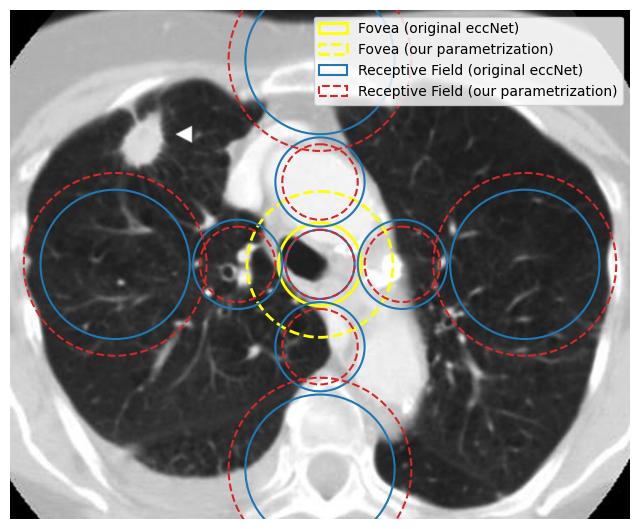

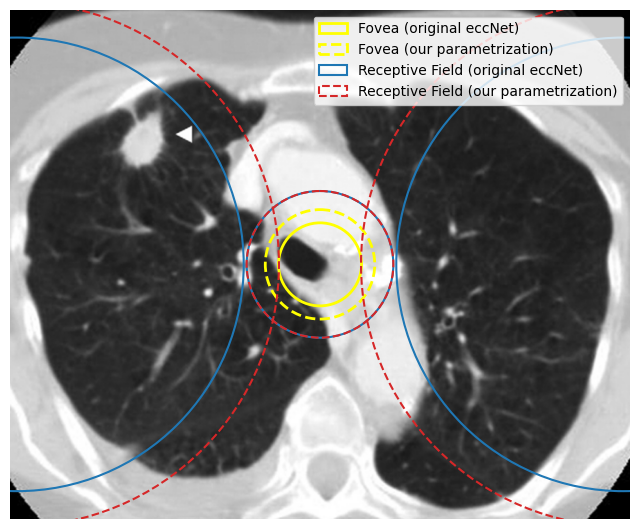

In [83]:
def plot_rf_comparison_on_image():
    """Circle positions come from the original eccNet RF sizes (non-overlapping); our RF
    sizes are drawn at the same positions and may overlap."""
    extent = (-img_w / 2, img_w / 2, img_h / 2, -img_h / 2)
    for layer in LAYERS:
        fig, ax = plt.subplots(figsize=(8, 7))
        ax.imshow(img, extent=extent)

        ax.add_patch(Circle((0, 0), dva_to_px(ECCNET_FOVEA_SIZE, ECCNET_DEG2PX[0]), fill=False,
                            color='yellow', linewidth=2, label='Fovea (original eccNet)'))
        ax.add_patch(Circle((0, 0), dva_to_px(FOVEA_SIZE_PER_LAYER[layer], deg2px[0]), fill=False,
                            color='yellow', linestyle='--', linewidth=2, label='Fovea (our parametrization)'))

        rf_eccnet = lambda e: effective_rf_diameter_px(e, ECCNET_ECC_SLOPE, ECCNET_DEG2PX, ECCNET_FOVEA_SIZE,
                                                       ECCNET_RF_MIN, POOL_STRIDE, CONV_LAYERS_PER_DEPTH,
                                                       CONV_KERNEL_SIZE, layer)
        rf_ours = lambda e: effective_rf_diameter_px(e, ecc_slope, deg2px, FOVEA_SIZE_PER_LAYER, RF_MIN,
                                                     POOL_STRIDE, CONV_LAYERS_PER_DEPTH, CONV_KERNEL_SIZE, layer)
        centres = [(0, 0, 0)]
        for e, _ in rf_positions(rf_eccnet, img_w / 2)[1:]:
            centres += [(e, 0, e), (-e, 0, e)]
        for e, _ in rf_positions(rf_eccnet, img_h / 2)[1:]:
            centres += [(0, e, e), (0, -e, e)]
        for i, (x, y, e) in enumerate(centres):
            ax.add_patch(Circle((x, y), rf_eccnet(e) / 2, fill=False, color='tab:blue', linewidth=1.5,
                                label='Receptive Field (original eccNet)' if i == 0 else None))
            ax.add_patch(Circle((x, y), rf_ours(e) / 2, fill=False, color='tab:red', linestyle='--',
                                linewidth=1.5, label='Receptive Field (our parametrization)' if i == 0 else None))

        ax.set_xlim(extent[0], extent[1])
        ax.set_ylim(extent[2], extent[3])
        ax.set_aspect('equal')
        ax.axis('off')
        ax.legend(loc='upper right')
        plt.show()

plot_rf_comparison_on_image()